In [68]:
import datetime
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import seaborn as sns

from djimaging.user.amacrine_cells_neuromodulation.notebooks.function_utils.helper_save_function import save_with_meta
from djimaging.user.amacrine_cells_neuromodulation.notebooks.function_utils.utils import pad_to_length, check_array_lengths
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [69]:
current_date = datetime.date.today().strftime("%Y%m%d")
print(current_date)

20261020


In [70]:
df = pd.read_pickle(f"../datasets/Processed/Averages_StrictlyQIFiltered_20261013.pkl")
df.shape

(2260, 48)

In [71]:
sum(df["cluster_gchirp"].value_counts().sort_index() / 2)

834.0

In [72]:
# Determine the set of cond2 values per (date, field) group
group_conditions = df.groupby(["date", "field"])["cond2"].apply(lambda s: set(s.unique()))

# Identify which groups are C1/C2 vs C1/DETANO
c2_groups = group_conditions[group_conditions == {"C1", "C2"}].index
detano_groups = group_conditions[group_conditions == {"C1", "DETANO"}].index

# Build a boolean mask using the (date, field) MultiIndex
df_idx = df.set_index(["date", "field"]).index

df_c2 = df[df_idx.isin(c2_groups)]
df_detano = df[df_idx.isin(detano_groups)]

print(f"C1/C2 groups: {len(c2_groups)}")
print(f"C1/DETANO groups: {len(detano_groups)}")

C1/C2 groups: 5
C1/DETANO groups: 5


# C1/C2

In [73]:
print(df_c2.shape)
print(sum(df_c2["cluster_gchirp"].value_counts().sort_index() / 2))

(1102, 48)
474.0


In [74]:
df_cluster0 = df_c2[df_c2["cluster_gchirp"] == 0]
print(df_cluster0.shape)

(150, 48)


In [75]:
df_c1_cluster0 = df_cluster0[df_cluster0["cond2"] == "C1"]
df_c2_cluster0 = df_cluster0[df_cluster0["cond2"] == "C2"]

print(df_c1_cluster0.shape)
print(df_c2_cluster0.shape)

(75, 48)
(75, 48)


In [76]:
sf = 500  # sampling frequency (Hz)

features = {
    "on":        [round(sf*2),  round(sf*5)],
    "off":       [round(sf*5),  round(sf*8)],
    "low_freq":  [round(sf*10), round(sf*13)],
    "high_freq": [round(sf*15), round(sf*18)],
    "low_cont":  [round(sf*20), round(sf*23)],
    "high_cont": [round(sf*25), round(sf*28)],
}

trace_col = "average_norm_gChirp"

In [77]:
max_end = max(end for _, end in features.values())

len_c1 = df_c1_cluster0[trace_col].apply(lambda x: len(np.asarray(x)))
len_c2 = df_c2_cluster0[trace_col].apply(lambda x: len(np.asarray(x)))

print("C1 trace lengths:", len_c1.unique())
print("C2 trace lengths:", len_c2.unique())
print("Required length (max window end):", max_end)

too_short = (len_c1 < max_end) | (len_c2 < max_end)
print(f"ROIs with traces too short: {too_short.sum()}")

C1 trace lengths: [16516]
C2 trace lengths: [16516]
Required length (max window end): 14000
ROIs with traces too short: 0


In [78]:
def safe_corr(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    if len(a) != len(b) or len(a) < 2:
        return np.nan
    mask = ~np.isnan(a) & ~np.isnan(b)
    a, b = a[mask], b[mask]
    if len(a) < 2 or np.std(a) == 0 or np.std(b) == 0:
        return np.nan
    return np.corrcoef(a, b)[0, 1]


def feature_correlations(trace0, trace1, features):
    trace0 = np.asarray(trace0, dtype=float)
    trace1 = np.asarray(trace1, dtype=float)
    return {name: safe_corr(trace0[start:end], trace1[start:end])
            for name, (start, end) in features.items()}

In [79]:
roi_id_col = None

key_cols = ["experimenter", "date", "exp_num", "raw_id", "field",
            "region", "cond1", "roi_id", "cluster_gchirp"]

# If roi_id was moved into the index in Cell 2, bring it back as a column
c1_k = df_c1_cluster0.reset_index() if roi_id_col is not None else df_c1_cluster0
c2_k = df_c2_cluster0.reset_index() if roi_id_col is not None else df_c2_cluster0

missing = [k for k in key_cols if k not in c1_k.columns or k not in c2_k.columns]
assert not missing, f"Missing key columns: {missing}"

# Keys that are identical in both dataframes for every ROI are stored once;
# keys that differ are stored as <key>_c1 and <key>_c2
differing = [k for k in key_cols
             if not (c1_k[k].astype(str).values == c2_k[k].astype(str).values).all()]
shared = [k for k in key_cols if k not in differing]
print("Shared keys:   ", shared)
print("Differing keys:", differing)

results = []
for i in range(len(c1_k)):
    row1 = c1_k.iloc[i]
    row2 = c2_k.iloc[i]

    rec = {k: row1[k] for k in shared}
    for k in differing:
        rec[f"{k}_c1"] = row1[k]
        rec[f"{k}_c2"] = row2[k]

    rec.update(feature_correlations(row1[trace_col], row2[trace_col], features))
    results.append(rec)

index_cols = shared + [f"{k}_{s}" for k in differing for s in ("c1", "c2")]
df_corr = pd.DataFrame(results).set_index(index_cols)
df_corr_flat = df_corr.reset_index()

assert df_corr.index.is_unique, "Primary keys do not uniquely identify ROIs!"
df_corr_flat.head()

Shared keys:    ['experimenter', 'date', 'exp_num', 'raw_id', 'field', 'region', 'cond1', 'roi_id', 'cluster_gchirp']
Differing keys: []


,experimenter,date,exp_num,raw_id,field,region,cond1,roi_id,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,Salomon,2025-09-08,2,1,XY7,RR,n,3,0.0,0.784835,0.462281,0.753795,0.400329,0.057516,0.453642
1,Salomon,2025-09-08,2,1,XY7,RR,n,5,0.0,0.883242,0.578496,0.859612,0.144386,0.274412,0.306527
2,Salomon,2025-09-08,2,1,XY7,RR,n,6,0.0,0.823055,0.738074,0.851499,0.099752,0.051668,0.187336
3,Salomon,2025-09-08,2,1,XY7,RR,n,9,0.0,0.766792,-0.083728,0.893611,-0.442164,0.086516,0.452096
4,Salomon,2025-09-08,2,1,XY7,RR,n,11,0.0,0.861441,-0.126435,0.737906,0.135643,0.149694,0.061223


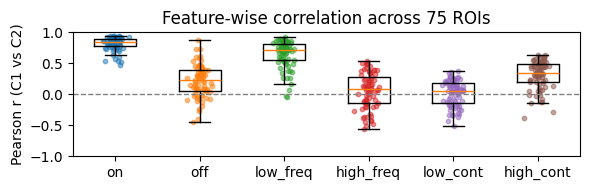

In [80]:
fig, ax = plt.subplots(figsize=(6, 2))

data = [df_corr[f].dropna().values for f in features]
ax.boxplot(data, tick_labels=list(features), showfliers=False)

for i, d in enumerate(data, start=1):
    jitter = np.random.normal(0, 0.06, size=len(d))
    ax.scatter(np.full(len(d), i) + jitter, d, s=10, alpha=0.5)

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("Pearson r (C1 vs C2)")
ax.set_title(f"Feature-wise correlation across {len(df_corr)} ROIs")
ax.set_ylim(-1,1)
plt.tight_layout()
plt.show()

In [81]:
cluster_ids = df["cluster_gchirp"].unique()
cluster_ids = cluster_ids[~np.isnan(cluster_ids)].astype(np.int32)
cluster_ids = np.sort(cluster_ids)

n_clusters = len(cluster_ids)
print(f"N clusters: {n_clusters}")
print(cluster_ids)

N clusters: 8
[0 1 2 3 4 5 6 7]


In [82]:
n_rois_c1 = []
n_rois_c2 = []

for i in cluster_ids:

    df_cluster = df_c2[df_c2["cluster_gchirp"] == i]

    #n_rois.append(df_cluster.shape[0] / 2)

    df_c1_cluster = df_cluster[df_cluster["cond2"] == "C1"]
    df_c2_cluster = df_cluster[df_cluster["cond2"] == "C2"]

    n_rois_c1.append(df_c1_cluster.shape[0])
    n_rois_c2.append(df_c2_cluster.shape[0])
    
print(sum(n_rois_c1))
print(sum(n_rois_c2))

474
474


In [83]:
corr_list = []

for i in cluster_ids:

    df_cluster = df_c2[df_c2["cluster_gchirp"] == i]

    df_c1_cluster = df_cluster[df_cluster["cond2"] == "C1"]
    df_c2_cluster = df_cluster[df_cluster["cond2"] == "C2"]

    max_end = max(end for _, end in features.values())

    len_c1 = df_c1_cluster[trace_col].apply(lambda x: len(np.asarray(x)))
    len_c2 = df_c2_cluster[trace_col].apply(lambda x: len(np.asarray(x)))

    too_short = (len_c1 < max_end) | (len_c2 < max_end)

    if too_short.sum() > 0:
        raise ValueError("One of the traces is too short")

    key_cols = ["experimenter", "date", "exp_num", "raw_id", "field",
            "region", "cond1", "roi_id", "cluster_gchirp"]

    # If roi_id was moved into the index in Cell 2, bring it back as a column
    c1_k = df_c1_cluster.reset_index() if roi_id_col is not None else df_c1_cluster
    c2_k = df_c2_cluster.reset_index() if roi_id_col is not None else df_c2_cluster
    
    missing = [k for k in key_cols if k not in c1_k.columns or k not in c2_k.columns]
    assert not missing, f"Missing key columns: {missing}"
    
    # Keys that are identical in both dataframes for every ROI are stored once;
    # keys that differ are stored as <key>_c1 and <key>_c2
    differing = [k for k in key_cols
                 if not (c1_k[k].astype(str).values == c2_k[k].astype(str).values).all()]
    shared = [k for k in key_cols if k not in differing]
    # print("Shared keys:   ", shared)
    # print("Differing keys:", differing)
    
    results = []
    for j in range(len(c1_k)):
        row1 = c1_k.iloc[j]
        row2 = c2_k.iloc[j]
    
        rec = {k: row1[k] for k in shared}
        for k in differing:
            rec[f"{k}_c1"] = row1[k]
            rec[f"{k}_c2"] = row2[k]
    
        rec.update(feature_correlations(row1[trace_col], row2[trace_col], features))
        results.append(rec)
    
    index_cols = shared + [f"{k}_{s}" for k in differing for s in ("c1", "c2")]
    df_corr = pd.DataFrame(results).set_index(index_cols)
    df_corr_flat = df_corr.reset_index()
    
    assert df_corr.index.is_unique, "Primary keys do not uniquely identify ROIs!"
    df_corr_flat.head()

    corr_list.append(df_corr_flat)
df_correlation = pd.concat(corr_list, ignore_index=True)

In [84]:
df_correlation.shape

(474, 15)

In [85]:
df_correlation["cluster_gchirp"].value_counts().sort_index()

cluster_gchirp
0.0    75
1.0    99
2.0    46
3.0    62
4.0    24
5.0    46
6.0    87
7.0    35
Name: count, dtype: int64

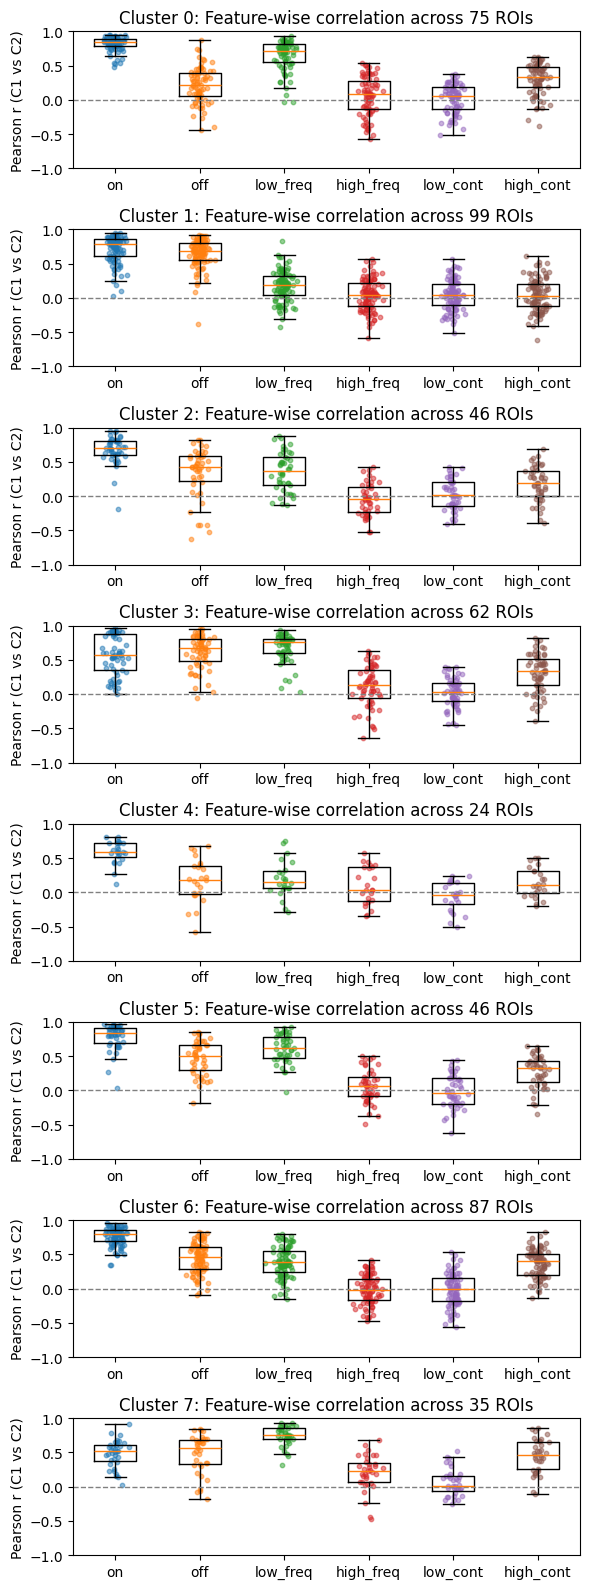

In [86]:
fig, axs = plt.subplots(n_clusters, 1, figsize=(6, 2 * n_clusters))

for i in cluster_ids:

    df_correlation_cluster = df_correlation[df_correlation["cluster_gchirp"] == i]

    data = [df_correlation_cluster[f].dropna().values for f in features]
    axs[i].boxplot(data, tick_labels=list(features), showfliers=False)
    
    for j, d in enumerate(data, start=1):
        jitter = np.random.normal(0, 0.06, size=len(d))
        axs[i].scatter(np.full(len(d), j) + jitter, d, s=10, alpha=0.5)
    
    axs[i].axhline(0, color="grey", linestyle="--", linewidth=1)
    axs[i].set_ylabel("Pearson r (C1 vs C2)")
    axs[i].set_title(f"Cluster {i}: Feature-wise correlation across {len(df_correlation_cluster)} ROIs")
    axs[i].set_ylim(-1,1)

plt.tight_layout()
plt.savefig(f"../plots/clustering/feature_correlations_boxplot_StrictlyFiltered_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

In [87]:
df_correlation_cluster0 = df_correlation[df_correlation["cluster_gchirp"] == 0]
print(df_correlation_cluster0.shape)

(75, 15)


In [88]:
print(df_correlation_cluster0.columns.to_list())

['experimenter', 'date', 'exp_num', 'raw_id', 'field', 'region', 'cond1', 'roi_id', 'cluster_gchirp', 'on', 'off', 'low_freq', 'high_freq', 'low_cont', 'high_cont']


In [89]:
columns = ["cluster_gchirp", "on", "off", "low_freq", "high_freq", "low_cont", "high_cont"]
columns

['cluster_gchirp',
 'on',
 'off',
 'low_freq',
 'high_freq',
 'low_cont',
 'high_cont']

In [90]:
mean_corr_cluster0 = df_correlation_cluster0[columns].mean(axis=0)
std_corr_cluster0 = df_correlation_cluster0[columns].std(axis=0)

print(mean_corr_cluster0)
print(std_corr_cluster0)

cluster_gchirp    0.000000
on                0.819301
off               0.217044
low_freq          0.650568
high_freq         0.053747
low_cont          0.016963
high_cont         0.308855
dtype: float64
cluster_gchirp    0.000000
on                0.106605
off               0.259708
low_freq          0.221531
high_freq         0.286710
low_cont          0.208116
high_cont         0.228738
dtype: float64


In [91]:
# Convert to a DataFrame with one row
heatmap_mean = pd.DataFrame(
    [mean_corr_cluster0.values],
    columns=columns,
    index=["Cluster 0"]
)

heatmap_std = pd.DataFrame(
    [std_corr_cluster0.values],
    columns=columns,
    index=["Cluster 0"]
)

print(heatmap_mean.shape)
print(heatmap_std.shape)

(1, 7)
(1, 7)


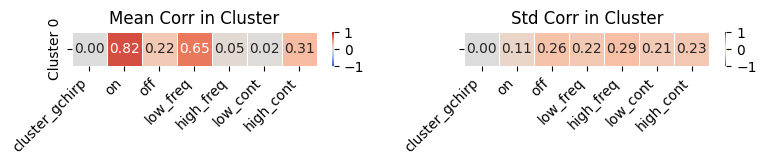

In [92]:
# Plot heatmap
fig, axs = plt.subplots(1, 2, figsize=(8, 1.75), sharey=True)

sns.heatmap(
    heatmap_mean,
    ax=axs[0],
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5
)

sns.heatmap(
    heatmap_std,
    ax=axs[1],
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar=True
)

for i in axs:
    i.set_xlabel("")
    i.set_ylabel("")
    i.set_xticklabels(i.get_xticklabels(), rotation=45, ha="right")

axs[0].set_title("Mean Corr in Cluster")
axs[1].set_title("Std Corr in Cluster")

plt.tight_layout()
plt.show()

In [93]:
# # Plot heatmaps
# fig, axs = plt.subplots(
#     n_clusters, 2,
#     figsize=(8, 1 * n_clusters),
#     sharex=True,
#     sharey=True,
#     squeeze=False
# )

mean_correlation = []
std_correlation = []

for row, i in enumerate(cluster_ids):

    df_correlation_cluster = df_correlation[
        df_correlation["cluster_gchirp"] == i
    ]

    mean_corr_cluster = df_correlation_cluster[columns].mean(axis=0)
    std_corr_cluster = df_correlation_cluster[columns].std(axis=0)

    # Convert to DataFrames with one row
    heatmap_mean_cluster = pd.DataFrame(
        [mean_corr_cluster.values],
        columns=columns,
        index=[f"cluster_gchirp {i}"]
    )

    heatmap_std_cluster = pd.DataFrame(
        [std_corr_cluster.values],
        columns=columns,
        index=[f"cluster_gchirp {i}"]
    )

    mean_correlation.append(heatmap_mean_cluster)
    std_correlation.append(heatmap_std_cluster)

df_mean_correlation = pd.concat(mean_correlation)
df_mean_correlation = df_mean_correlation.reset_index(drop=True)

df_std_correlation = pd.concat(std_correlation)
df_std_correlation = df_std_correlation.reset_index(drop=True)


#     # Mean correlation heatmap
#     sns.heatmap(
#         heatmap_mean_cluster,
#         ax=axs[row, 0],
#         cmap="coolwarm",
#         vmin=-1,
#         vmax=1,
#         center=0,
#         annot=True,
#         fmt=".2f",
#         linewidths=0.5
#     )

#     # Standard deviation heatmap
#     sns.heatmap(
#         heatmap_std_cluster,
#         ax=axs[row, 1],
#         cmap="coolwarm",
#         vmin=-1,
#         vmax=1,
#         center=0,
#         annot=True,
#         fmt=".2f",
#         linewidths=0.5,
#         cbar=True
#     )

# plt.tight_layout()
# plt.show()

In [94]:
df_mean_correlation

,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,0.0,0.819301,0.217044,0.650568,0.053747,0.016963,0.308855
1,1.0,0.716259,0.656226,0.175460,0.041010,0.036592,0.044976
2,2.0,0.675008,0.333053,0.360448,-0.049584,0.017683,0.180218
3,3.0,0.568264,0.618627,0.683903,0.114822,0.024176,0.307289
4,4.0,0.585970,0.173671,0.194245,0.097843,-0.063770,0.141210
5,5.0,0.787752,0.475993,0.614639,0.059136,-0.011578,0.275451
6,6.0,0.757942,0.447292,0.389991,-0.015434,-0.017286,0.367114
7,7.0,0.484448,0.478986,0.741861,0.207149,0.061531,0.452733


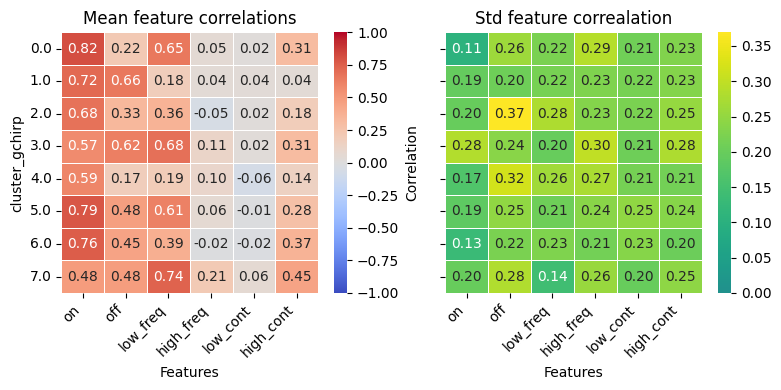

In [96]:
# Select the six columns to plot
columns_plot = df_mean_correlation.columns.drop("cluster_gchirp")
data_mean = df_mean_correlation[columns_plot]
data_std = df_std_correlation[columns_plot]

# Create heatmap
fig, ax = plt.subplots(1, 2, figsize=(8, 4), sharey=True)

sns.heatmap(
    data_mean,
    ax=ax[0],
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Correlation"},
    yticklabels=df_mean_correlation["cluster_gchirp"]
)

sns.heatmap(
    data_std,
    ax=ax[1],
    cmap="viridis",
    vmin=0,
    vmax=data_std.values.max(),
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    #cbar_kws={"label": "Std"},
    yticklabels=df_std_correlation["cluster_gchirp"]
)

ax[0].set_ylabel("cluster_gchirp")
ax[0].set_title("Mean feature correlations")
ax[1].set_title("Std feature correalation")

for i in ax:

    # Label axes
    i.set_xlabel("Features")
    i.set_xticklabels(columns_plot, rotation=45, ha="right")
    i.set_yticklabels(df_mean_correlation["cluster_gchirp"], rotation=0)

plt.tight_layout()
plt.savefig(f"../plots/clustering/C1C2_feature_correlations_mean_heatmap_StrictlyFiltered_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

# Continue for C1 / DETA/NO

In [97]:
df_detano.shape

(1158, 48)

In [98]:
n_rois_c1 = []
n_rois_no = []

for i in cluster_ids:

    df_cluster = df_detano[df_detano["cluster_gchirp"] == i]

    #n_rois.append(df_cluster.shape[0] / 2)

    df_c1_cluster = df_cluster[df_cluster["cond2"] == "C1"]
    df_no_cluster = df_cluster[df_cluster["cond2"] == "DETANO"]

    n_rois_c1.append(df_c1_cluster.shape[0])
    n_rois_no.append(df_no_cluster.shape[0])
    
print(sum(n_rois_c1))
print(sum(n_rois_no))
print(n_rois_c1)

360
360
[73, 0, 29, 150, 55, 21, 17, 15]


In [99]:
df_cluster_no = df_detano[df_detano["cluster_gchirp"] == 1]
df_cluster_no.shape

(0, 48)

In [100]:
df_c1_cluster = df_cluster_no[df_cluster_no["cond2"] == "C1"]
df_no_cluster = df_cluster_no[df_cluster_no["cond2"] == "DETANO"]

print(df_c1_cluster.shape)
print(df_no_cluster.shape)

(0, 48)
(0, 48)


In [101]:
print(len(df_c1_cluster))

0


In [102]:
roi_id_col = None

key_cols = ["experimenter", "date", "exp_num", "raw_id", "field",
            "region", "cond1", "roi_id", "cluster_gchirp"]

# If roi_id was moved into the index in Cell 2, bring it back as a column
c1_k = df_c1_cluster.reset_index() if roi_id_col is not None else df_c1_cluster
no_k = df_no_cluster.reset_index() if roi_id_col is not None else df_no_cluster

missing = [k for k in key_cols if k not in c1_k.columns or k not in no_k.columns]
assert not missing, f"Missing key columns: {missing}"

# Keys that are identical in both dataframes for every ROI are stored once;
# keys that differ are stored as <key>_c1 and <key>_c2
differing = [k for k in key_cols
             if not (c1_k[k].astype(str).values == no_k[k].astype(str).values).all()]
shared = [k for k in key_cols if k not in differing]
print("Shared keys:   ", shared)
print("Differing keys:", differing)

results = []
for i in range(len(c1_k)):
    row1 = c1_k.iloc[i]
    row2 = no_k.iloc[i]

    rec = {k: row1[k] for k in shared}
    for k in differing:
        rec[f"{k}_c1"] = row1[k]
        rec[f"{k}_c2"] = row2[k]

    rec.update(feature_correlations(row1[trace_col], row2[trace_col], features))
    results.append(rec)

index_cols = shared + [f"{k}_{s}" for k in differing for s in ("c1", "c2")]
df_corr = pd.DataFrame(results).set_index(index_cols)
df_corr_flat = df_corr.reset_index()

assert df_corr.index.is_unique, "Primary keys do not uniquely identify ROIs!"
df_corr_flat.head()

Shared keys:    ['experimenter', 'date', 'exp_num', 'raw_id', 'field', 'region', 'cond1', 'roi_id', 'cluster_gchirp']
Differing keys: []


KeyError: "None of ['experimenter', 'date', 'exp_num', 'raw_id', 'field', 'region', 'cond1', 'roi_id', 'cluster_gchirp'] are in the columns"

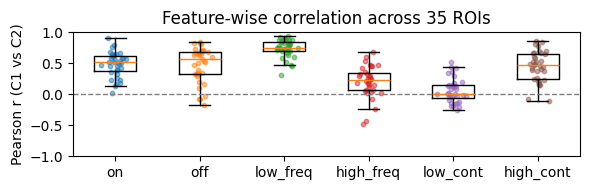

In [103]:
fig, ax = plt.subplots(figsize=(6, 2))

data = [df_corr[f].dropna().values for f in features]
ax.boxplot(data, tick_labels=list(features), showfliers=False)

for i, d in enumerate(data, start=1):
    jitter = np.random.normal(0, 0.06, size=len(d))
    ax.scatter(np.full(len(d), i) + jitter, d, s=10, alpha=0.5)

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("Pearson r (C1 vs C2)")
ax.set_title(f"Feature-wise correlation across {len(df_corr)} ROIs")
ax.set_ylim(-1,1)
plt.tight_layout()
plt.show()

In [104]:
corr_list = []

for i in cluster_ids:

    df_cluster = df_detano[df_detano["cluster_gchirp"] == i]

    df_c1_cluster = df_cluster[df_cluster["cond2"] == "C1"]
    df_no_cluster = df_cluster[df_cluster["cond2"] == "DETANO"]

    if len(df_c1_cluster) == 0:
        continue
    
    max_end = max(end for _, end in features.values())

    len_c1 = df_c1_cluster[trace_col].apply(lambda x: len(np.asarray(x)))
    len_no = df_no_cluster[trace_col].apply(lambda x: len(np.asarray(x)))

    too_short = (len_c1 < max_end) | (len_no < max_end)

    if too_short.sum() > 0:
        raise ValueError("One of the traces is too short")

    key_cols = ["experimenter", "date", "exp_num", "raw_id", "field",
            "region", "cond1", "roi_id", "cluster_gchirp"]

    # If roi_id was moved into the index in Cell 2, bring it back as a column
    c1_k = df_c1_cluster.reset_index() if roi_id_col is not None else df_c1_cluster
    no_k = df_no_cluster.reset_index() if roi_id_col is not None else df_no_cluster
    
    missing = [k for k in key_cols if k not in c1_k.columns or k not in no_k.columns]
    assert not missing, f"Missing key columns: {missing}"
    
    # Keys that are identical in both dataframes for every ROI are stored once;
    # keys that differ are stored as <key>_c1 and <key>_no
    differing = [k for k in key_cols
                 if not (c1_k[k].astype(str).values == no_k[k].astype(str).values).all()]
    shared = [k for k in key_cols if k not in differing]
    # print("Shared keys:   ", shared)
    # print("Differing keys:", differing)
    
    results = []
    for j in range(len(c1_k)):
        row1 = c1_k.iloc[j]
        row2 = no_k.iloc[j]
    
        rec = {k: row1[k] for k in shared}
        for k in differing:
            rec[f"{k}_c1"] = row1[k]
            rec[f"{k}_no"] = row2[k]
    
        rec.update(feature_correlations(row1[trace_col], row2[trace_col], features))
        results.append(rec)
    
    index_cols = shared + [f"{k}_{s}" for k in differing for s in ("c1", "no")]
    df_corr = pd.DataFrame(results).set_index(index_cols)
    df_corr_flat = df_corr.reset_index()
    
    assert df_corr.index.is_unique, "Primary keys do not uniquely identify ROIs!"
    df_corr_flat.head()

    corr_list.append(df_corr_flat)
df_correlation_no = pd.concat(corr_list, ignore_index=True)
print(df_correlation_no.shape)
df_correlation_no.head()

(360, 15)


,experimenter,date,exp_num,raw_id,field,region,cond1,roi_id,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,Salomon,2025-09-08,2,1,XY2,RR,v,164,0.0,0.573850,-0.022286,-0.026509,0.095920,0.137113,-0.464097
1,Salomon,2025-09-08,2,1,XY2,RR,v,184,0.0,0.719981,-0.147137,0.025101,-0.035362,0.198239,-0.513977
2,Salomon,2025-09-08,2,1,XY8,RR,n,57,0.0,0.923133,0.287509,0.131057,0.109999,-0.033638,-0.084197
3,Salomon,2025-09-08,2,1,XY8,RR,n,58,0.0,0.902244,-0.072260,0.470118,0.350359,0.105117,-0.141776
4,Salomon,2025-09-08,2,1,XY8,RR,n,67,0.0,0.867701,0.080621,0.415275,0.130493,0.160739,-0.125151


In [105]:
results

[{'experimenter': 'Salomon',
  'date': datetime.date(2025, 10, 23),
  'exp_num': 2,
  'raw_id': 1,
  'field': 'XY2',
  'region': 'RR',
  'cond1': 'd',
  'roi_id': 54,
  'cluster_gchirp': 7.0,
  'on': 0.6274719571268769,
  'off': 0.31825074975791473,
  'low_freq': -0.14537533713581968,
  'high_freq': -0.26903619779870397,
  'low_cont': -0.3725522789840295,
  'high_cont': -0.05012410785598929},
 {'experimenter': 'Salomon',
  'date': datetime.date(2025, 10, 23),
  'exp_num': 2,
  'raw_id': 1,
  'field': 'XY2',
  'region': 'RR',
  'cond1': 'd',
  'roi_id': 83,
  'cluster_gchirp': 7.0,
  'on': 0.7348609656783668,
  'off': 0.3420431538529171,
  'low_freq': 0.41640444748153566,
  'high_freq': 0.1340160543235677,
  'low_cont': -0.20899409588425566,
  'high_cont': 0.4461532695686574},
 {'experimenter': 'Salomon',
  'date': datetime.date(2025, 10, 23),
  'exp_num': 2,
  'raw_id': 1,
  'field': 'XY2',
  'region': 'RR',
  'cond1': 'd',
  'roi_id': 97,
  'cluster_gchirp': 7.0,
  'on': 0.48226310588

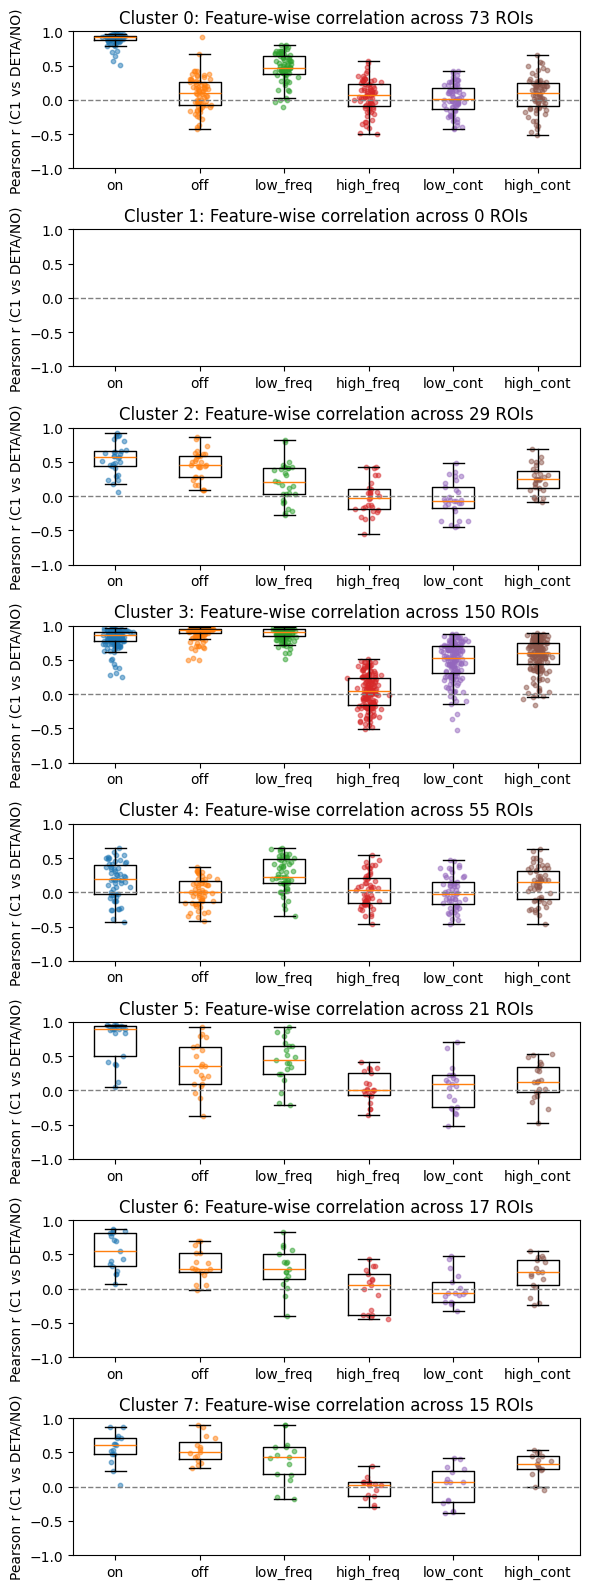

In [107]:
fig, axs = plt.subplots(n_clusters, 1, figsize=(6, 2 * n_clusters))

for i in cluster_ids:

    df_correlation_cluster = df_correlation_no[df_correlation_no["cluster_gchirp"] == i]

    data = [df_correlation_cluster[f].dropna().values for f in features]
    axs[i].boxplot(data, tick_labels=list(features), showfliers=False)
    
    for j, d in enumerate(data, start=1):
        jitter = np.random.normal(0, 0.06, size=len(d))
        axs[i].scatter(np.full(len(d), j) + jitter, d, s=10, alpha=0.5)
    
    axs[i].axhline(0, color="grey", linestyle="--", linewidth=1)
    axs[i].set_ylabel("Pearson r (C1 vs DETA/NO)")
    axs[i].set_title(f"Cluster {i}: Feature-wise correlation across {len(df_correlation_cluster)} ROIs")
    axs[i].set_ylim(-1,1)

plt.tight_layout()
plt.savefig(f"../plots/clustering/C1NO_feature_correlations_boxplot_StrictlyFilterd_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

In [108]:
df_correlation_cluster = df_correlation_no[df_correlation_no["cluster_gchirp"] == 0]
df_correlation_cluster

,experimenter,date,exp_num,raw_id,field,region,cond1,roi_id,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,Salomon,2025-09-08,2,1,XY2,RR,v,164,0.0,0.573850,-0.022286,-0.026509,0.095920,0.137113,-0.464097
1,Salomon,2025-09-08,2,1,XY2,RR,v,184,0.0,0.719981,-0.147137,0.025101,-0.035362,0.198239,-0.513977
2,Salomon,2025-09-08,2,1,XY8,RR,n,57,0.0,0.923133,0.287509,0.131057,0.109999,-0.033638,-0.084197
3,Salomon,2025-09-08,2,1,XY8,RR,n,58,0.0,0.902244,-0.072260,0.470118,0.350359,0.105117,-0.141776
4,Salomon,2025-09-08,2,1,XY8,RR,n,67,0.0,0.867701,0.080621,0.415275,0.130493,0.160739,-0.125151
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68,Salomon,2025-09-08,2,1,XY8,RR,n,257,0.0,0.640643,0.419035,0.278715,-0.028770,0.414909,0.136439
69,Salomon,2025-10-23,2,1,XY2,RR,d,52,0.0,0.957487,-0.073847,0.214974,0.094943,0.045652,-0.027890
70,Salomon,2025-10-23,2,1,XY2,RR,d,57,0.0,0.832251,0.056510,0.238797,-0.355500,0.124422,0.066366
71,Salomon,2025-10-23,2,1,XY2,RR,d,58,0.0,0.935380,0.057221,-0.006520,-0.185515,-0.085860,0.199690


In [109]:
columns

['cluster_gchirp',
 'on',
 'off',
 'low_freq',
 'high_freq',
 'low_cont',
 'high_cont']

In [110]:
mean_correlation_no = []
std_correlation_no = []

for row, i in enumerate(cluster_ids):

    df_correlation_cluster = df_correlation_no[
        df_correlation_no["cluster_gchirp"] == i
    ]

    mean_corr_cluster = df_correlation_cluster[columns].mean(axis=0)
    std_corr_cluster = df_correlation_cluster[columns].std(axis=0)

    # Convert to DataFrames with one row
    heatmap_mean_cluster = pd.DataFrame(
        [mean_corr_cluster.values],
        columns=columns,
        index=[f"cluster_gchirp {i}"]
    )

    heatmap_std_cluster = pd.DataFrame(
        [std_corr_cluster.values],
        columns=columns,
        index=[f"cluster_gchirp {i}"]
    )

    mean_correlation_no.append(heatmap_mean_cluster)
    std_correlation_no.append(heatmap_std_cluster)

df_mean_correlation_no = pd.concat(mean_correlation_no)
df_mean_correlation_no = df_mean_correlation_no.reset_index(drop=True)

df_std_correlation_no = pd.concat(std_correlation_no)
df_std_correlation_no = df_std_correlation_no.reset_index(drop=True)


In [111]:
df_mean_correlation_no

,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,0.0,0.886991,0.093016,0.471508,0.055796,0.017001,0.081403
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2.0,0.549817,0.449291,0.201874,-0.023102,-0.041603,0.246285
3,3.0,0.823559,0.907360,0.887899,0.040863,0.482649,0.565530
4,4.0,0.173682,0.010171,0.263710,0.033274,0.000801,0.120098
5,5.0,0.738922,0.352891,0.435221,0.040433,0.045327,0.127944
6,6.0,0.540306,0.338138,0.290439,-0.025763,-0.005911,0.209042
7,7.0,0.558769,0.543662,0.391138,-0.015578,0.010321,0.315630


In [112]:
data_std_no = df_std_correlation_no[columns]
np.nanmax(data_std_no)

0.3435070140269144

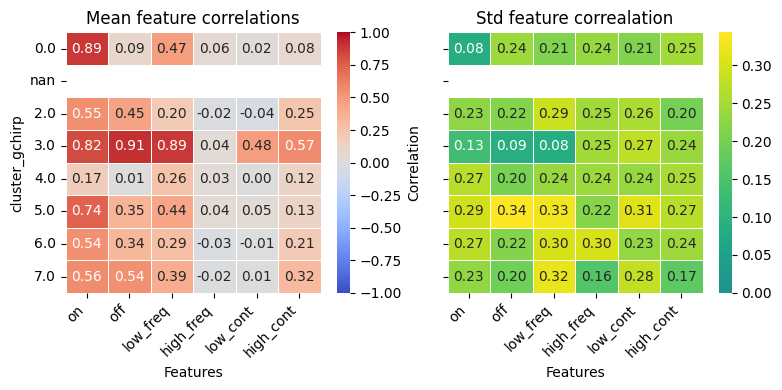

In [113]:
# Select the six columns to plot
columns_plot = df_mean_correlation_no.columns.drop("cluster_gchirp")
data_mean_no = df_mean_correlation_no[columns_plot]
data_std_no = df_std_correlation_no[columns_plot]

# Create heatmap
fig, ax = plt.subplots(1, 2, figsize=(8, 4), sharey=True)

sns.heatmap(
    data_mean_no,
    ax=ax[0],
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Correlation"},
    yticklabels=df_mean_correlation_no["cluster_gchirp"]
)

sns.heatmap(
    data_std_no,
    ax=ax[1],
    cmap="viridis",
    vmin=0,
    vmax=np.nanmax(data_std_no),
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    #cbar_kws={"label": "Std"},
    yticklabels=df_std_correlation_no["cluster_gchirp"]
)

ax[0].set_ylabel("cluster_gchirp")
ax[0].set_title("Mean feature correlations")
ax[1].set_title("Std feature correalation")

for i in ax:

    # Label axes
    i.set_xlabel("Features")
    i.set_xticklabels(columns_plot, rotation=45, ha="right")
    i.set_yticklabels(df_mean_correlation_no["cluster_gchirp"], rotation=0)

plt.tight_layout()
# plt.savefig(f"../plots/clustering/C1NO_feature_correlations_mean_heatmap_{current_date}.png",
#             dpi=300,
#             bbox_inches="tight")
plt.show()

# C2 / DETA/NO

- to inspect whether differences appear in C2 / DETA/NO the correlation matrices will be divided with one another

In [114]:
df_mean_correlation

,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,0.0,0.819301,0.217044,0.650568,0.053747,0.016963,0.308855
1,1.0,0.716259,0.656226,0.175460,0.041010,0.036592,0.044976
2,2.0,0.675008,0.333053,0.360448,-0.049584,0.017683,0.180218
3,3.0,0.568264,0.618627,0.683903,0.114822,0.024176,0.307289
4,4.0,0.585970,0.173671,0.194245,0.097843,-0.063770,0.141210
5,5.0,0.787752,0.475993,0.614639,0.059136,-0.011578,0.275451
6,6.0,0.757942,0.447292,0.389991,-0.015434,-0.017286,0.367114
7,7.0,0.484448,0.478986,0.741861,0.207149,0.061531,0.452733


In [115]:
df_mean_correlation_no

,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,0.0,0.886991,0.093016,0.471508,0.055796,0.017001,0.081403
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2.0,0.549817,0.449291,0.201874,-0.023102,-0.041603,0.246285
3,3.0,0.823559,0.907360,0.887899,0.040863,0.482649,0.565530
4,4.0,0.173682,0.010171,0.263710,0.033274,0.000801,0.120098
5,5.0,0.738922,0.352891,0.435221,0.040433,0.045327,0.127944
6,6.0,0.540306,0.338138,0.290439,-0.025763,-0.005911,0.209042
7,7.0,0.558769,0.543662,0.391138,-0.015578,0.010321,0.315630


In [116]:
columns_plot

Index(['on', 'off', 'low_freq', 'high_freq', 'low_cont', 'high_cont'], dtype='object')

In [117]:
np.abs(df_mean_correlation[columns_plot]) / np.abs(df_mean_correlation_no[columns_plot])

,on,off,low_freq,high_freq,low_cont,high_cont
0,0.923687,2.333389,1.379761,0.963280,0.997808,3.794156
1,NaN,NaN,NaN,NaN,NaN,NaN
2,1.227696,0.741285,1.785505,2.146350,0.425045,0.731744
3,0.690010,0.681788,0.770249,2.809903,0.050090,0.543365
4,3.373810,17.074551,0.736587,2.940554,79.621815,1.175790
5,1.066083,1.348838,1.412245,1.462571,0.255432,2.152900
6,1.402800,1.322811,1.342760,0.599083,2.924442,1.756175
7,0.866992,0.881036,1.896673,13.297845,5.961643,1.434377


In [118]:
df_mean_correlation_c2_no = df_mean_correlation[columns_plot] - df_mean_correlation_no[columns_plot]
df_mean_correlation_c2_no

,on,off,low_freq,high_freq,low_cont,high_cont
0,-0.067689,0.124027,0.179060,-0.002049,-0.000037,0.227452
1,NaN,NaN,NaN,NaN,NaN,NaN
2,0.125191,-0.116238,0.158573,-0.026482,0.059286,-0.066068
3,-0.255295,-0.288732,-0.203996,0.073959,-0.458473,-0.258240
4,0.412288,0.163500,-0.069465,0.064569,-0.064570,0.021112
5,0.048830,0.123102,0.179418,0.018703,-0.056904,0.147507
6,0.217635,0.109155,0.099551,0.010329,-0.011375,0.158072
7,-0.074321,-0.064676,0.350723,0.222727,0.051210,0.137102


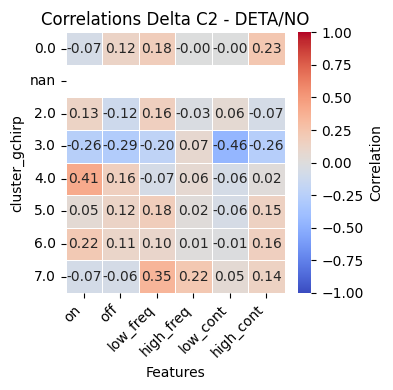

In [120]:
# Select the six columns to plot
#columns_plot = df_mean_correlation_no.columns.drop("cluster_gchirp")
data_matrix = df_mean_correlation_c2_no

# Create heatmap
fig, ax = plt.subplots(1, 1, figsize=(4, 4), sharey=True)

sns.heatmap(
    data_matrix,
    ax=ax,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Correlation"},
    yticklabels=df_mean_correlation_no["cluster_gchirp"]
)

ax.set_ylabel("cluster_gchirp")
ax.set_title("Correlations Delta C2 - DETA/NO")

ax.set_xlabel("Features")
ax.set_xticklabels(columns_plot, rotation=45, ha="right")
ax.set_yticklabels(df_mean_correlation_no["cluster_gchirp"], rotation=0)

plt.tight_layout()
plt.savefig(f"../plots/clustering/C2NO_feature_correlations_mean_heatmap_StrictlyFiltered_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

# C2 / DETA/NO

- to inspect whether differences appear in C2 / DETA/NO the correlation matrices will be divided with one another

In [121]:
df_mean_correlation

,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,0.0,0.819301,0.217044,0.650568,0.053747,0.016963,0.308855
1,1.0,0.716259,0.656226,0.175460,0.041010,0.036592,0.044976
2,2.0,0.675008,0.333053,0.360448,-0.049584,0.017683,0.180218
3,3.0,0.568264,0.618627,0.683903,0.114822,0.024176,0.307289
4,4.0,0.585970,0.173671,0.194245,0.097843,-0.063770,0.141210
5,5.0,0.787752,0.475993,0.614639,0.059136,-0.011578,0.275451
6,6.0,0.757942,0.447292,0.389991,-0.015434,-0.017286,0.367114
7,7.0,0.484448,0.478986,0.741861,0.207149,0.061531,0.452733


In [122]:
df_mean_correlation_no

,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,0.0,0.886991,0.093016,0.471508,0.055796,0.017001,0.081403
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2.0,0.549817,0.449291,0.201874,-0.023102,-0.041603,0.246285
3,3.0,0.823559,0.907360,0.887899,0.040863,0.482649,0.565530
4,4.0,0.173682,0.010171,0.263710,0.033274,0.000801,0.120098
5,5.0,0.738922,0.352891,0.435221,0.040433,0.045327,0.127944
6,6.0,0.540306,0.338138,0.290439,-0.025763,-0.005911,0.209042
7,7.0,0.558769,0.543662,0.391138,-0.015578,0.010321,0.315630


In [123]:
columns_plot

Index(['on', 'off', 'low_freq', 'high_freq', 'low_cont', 'high_cont'], dtype='object')

In [124]:
np.abs(df_mean_correlation[columns_plot]) / np.abs(df_mean_correlation_no[columns_plot])

,on,off,low_freq,high_freq,low_cont,high_cont
0,0.923687,2.333389,1.379761,0.963280,0.997808,3.794156
1,NaN,NaN,NaN,NaN,NaN,NaN
2,1.227696,0.741285,1.785505,2.146350,0.425045,0.731744
3,0.690010,0.681788,0.770249,2.809903,0.050090,0.543365
4,3.373810,17.074551,0.736587,2.940554,79.621815,1.175790
5,1.066083,1.348838,1.412245,1.462571,0.255432,2.152900
6,1.402800,1.322811,1.342760,0.599083,2.924442,1.756175
7,0.866992,0.881036,1.896673,13.297845,5.961643,1.434377


In [125]:
df_mean_correlation_c2_no = df_mean_correlation[columns_plot] - df_mean_correlation_no[columns_plot]
df_mean_correlation_c2_no

,on,off,low_freq,high_freq,low_cont,high_cont
0,-0.067689,0.124027,0.179060,-0.002049,-0.000037,0.227452
1,NaN,NaN,NaN,NaN,NaN,NaN
2,0.125191,-0.116238,0.158573,-0.026482,0.059286,-0.066068
3,-0.255295,-0.288732,-0.203996,0.073959,-0.458473,-0.258240
4,0.412288,0.163500,-0.069465,0.064569,-0.064570,0.021112
5,0.048830,0.123102,0.179418,0.018703,-0.056904,0.147507
6,0.217635,0.109155,0.099551,0.010329,-0.011375,0.158072
7,-0.074321,-0.064676,0.350723,0.222727,0.051210,0.137102


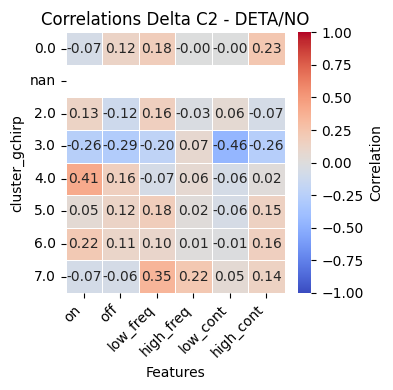

In [126]:
# Select the six columns to plot
#columns_plot = df_mean_correlation_no.columns.drop("cluster_gchirp")
data_matrix = df_mean_correlation_c2_no

# Create heatmap
fig, ax = plt.subplots(1, 1, figsize=(4, 4), sharey=True)

sns.heatmap(
    data_matrix,
    ax=ax,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Correlation"},
    yticklabels=df_mean_correlation_no["cluster_gchirp"]
)

ax.set_ylabel("cluster_gchirp")
ax.set_title("Correlations Delta C2 - DETA/NO")

ax.set_xlabel("Features")
ax.set_xticklabels(columns_plot, rotation=45, ha="right")
ax.set_yticklabels(df_mean_correlation_no["cluster_gchirp"], rotation=0)

plt.tight_layout()
plt.savefig(f"../plots/clustering/C2NO_feature_correlations_mean_heatmap_StrictlyFiltered_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()